In [2]:
import json
import numpy as np
import easyocr
from datasets import load_dataset

ds = load_dataset("naver-clova-ix/cord-v2", cache_dir="../data")
reader = easyocr.Reader(["en"], gpu=True, model_storage_directory="../data/easyocr_models")

In [3]:
sample = ds["validation"][0]
image = sample["image"].convert("RGB")

results = reader.readtext(np.array(image))

print(f"{len(results)} Textstücke gefunden\n")
for bbox, text, conf in results[:15]:
    print(f"{conf:.2f}  {text}")

14 Textstücke gefunden

0.63  REAL GANACHE
1.00  16,500
0.46  EGG TART
1.00  13,000
0.29  PIZZA TOAST
1.00  16,000
0.99  TOTAL
1.00  45_
0.49  J
1.00  500
0.88  CASH
0.74  50,000
0.99  CHANGE
0.95  4,500


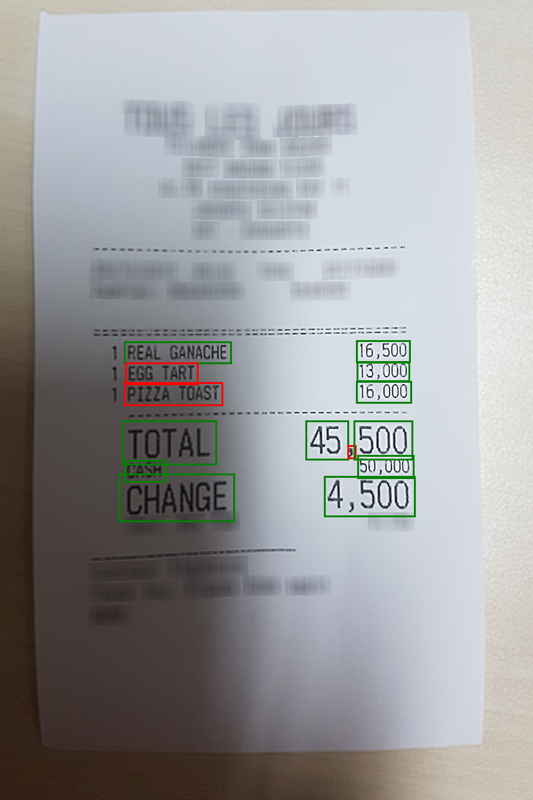

In [4]:
from PIL import ImageDraw

vis = image.copy()
draw = ImageDraw.Draw(vis)
for bbox, text, conf in results:
    points = [(int(x), int(y)) for x, y in bbox]
    color = "green" if conf > 0.5 else "red"
    draw.polygon(points, outline=color, width=3)

vis.thumbnail((800, 800))
vis

In [5]:
def group_into_lines(results, y_tolerance=0.5):
    """Fügt OCR-Textstücke zu Zeilen zusammen, sortiert von oben nach unten und links nach rechts."""
    boxes = []
    for bbox, text, conf in results:
        xs = [p[0] for p in bbox]
        ys = [p[1] for p in bbox]
        boxes.append({
            "text": text,
            "x": min(xs),
            "y_center": (min(ys) + max(ys)) / 2,
            "height": max(ys) - min(ys),
        })

    boxes.sort(key=lambda b: b["y_center"])

    lines = []
    for box in boxes:
        if lines and abs(box["y_center"] - lines[-1]["y_center"]) < y_tolerance * box["height"]:
            lines[-1]["boxes"].append(box)
        else:
            lines.append({"y_center": box["y_center"], "boxes": [box]})

    text_lines = []
    for line in lines:
        line["boxes"].sort(key=lambda b: b["x"])
        text_lines.append("  ".join(b["text"] for b in line["boxes"]))
    return text_lines

In [6]:
lines = group_into_lines(results)
print("=== OCR (zeilenweise) ===")
print("\n".join(lines))

print("\n=== Ground Truth ===")
gt = json.loads(sample["ground_truth"])["gt_parse"]
print(json.dumps(gt, indent=2, ensure_ascii=False))

=== OCR (zeilenweise) ===
REAL GANACHE  16,500
EGG TART  13,000
PIZZA TOAST  16,000
TOTAL  45_  500
J
CASH  50,000
CHANGE  4,500

=== Ground Truth ===
{
  "menu": [
    {
      "nm": "REAL GANACHE",
      "cnt": "1",
      "price": "16,500"
    },
    {
      "nm": "EGG TART",
      "cnt": "1",
      "price": "13,000"
    },
    {
      "nm": "PIZZA TOAST",
      "cnt": "1",
      "price": "16,000"
    }
  ],
  "total": {
    "total_price": "45,500",
    "cashprice": "50,000",
    "changeprice": "4,500"
  }
}


In [7]:
results_tuned = reader.readtext(np.array(image), mag_ratio=2.0, low_text=0.3)
print("\n".join(group_into_lines(results_tuned)))

ID I
REAL GANACHE  16,500
egg TART  13,000
PIZZa TOAST  16,000
TOTAL  45,500
CASH  50,000
CHANGE  4,500


In [8]:
import sys
sys.path.append("..")

import pandas as pd
from src.utils import FIELDS, parse_ground_truth, get_field, normalize_number
from src.ocr import group_into_lines

In [9]:
def load_ocr(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def field_coverage(ocr_payload, gt_strings):
    """Prüft für jedes Feld jedes Zettels, ob der richtige Betrag in einer OCR-Zeile vorkommt."""
    rows = []
    for record in ocr_payload["records"]:
        gt = parse_ground_truth(gt_strings[record["index"]])
        lines = group_into_lines(record["words"])
        line_digits = [normalize_number(line) or "" for line in lines]

        for section, key in FIELDS:
            gt_value = normalize_number(get_field(gt, section, key))
            if gt_value is None:
                continue
            found = any(gt_value in digits for digits in line_digits)
            rows.append({
                "index": record["index"],
                "field": f"{section}.{key}",
                "gt": gt_value,
                "found": found,
            })
    return pd.DataFrame(rows)

In [10]:
val_gt = list(ds["validation"]["ground_truth"])

cov_default = field_coverage(load_ocr("../results/ocr/validation.json"), val_gt)
cov_tuned = field_coverage(load_ocr("../results/ocr/validation_tuned.json"), val_gt)

summary = pd.DataFrame({
    "n": cov_default.groupby("field").size(),
    "default": cov_default.groupby("field")["found"].mean() * 100,
    "tuned": cov_tuned.groupby("field")["found"].mean() * 100,
})
summary.loc["ALL"] = [len(cov_default), cov_default["found"].mean() * 100, cov_tuned["found"].mean() * 100]
summary.round(1)

,n,default,tuned
field,,,
sub_total.subtotal_price,67,82.1,85.1
sub_total.tax_price,47,83.0,80.9
total.cashprice,64,50.0,54.7
total.changeprice,64,68.8,65.6
total.total_price,98,74.5,78.6
ALL,340,71.5,73.2


In [11]:
missed = cov_default[~cov_default["found"]]
print(f"{len(missed)} Felder nicht im OCR-Text gefunden\n")
missed

97 Felder nicht im OCR-Text gefunden



,index,field,gt,found
3,1,total.total_price,23000,False
4,1,total.cashprice,50000,False
5,1,total.changeprice,27000,False
9,2,total.changeprice,80000,False
18,4,total.cashprice,50000,False
...,...,...,...,...
324,95,total.changeprice,20000,False
325,95,sub_total.tax_price,2700,False
331,97,total.cashprice,30000,False
333,98,total.total_price,100000,False


Zettel 1, gesucht: [{'field': 'total.total_price', 'gt': '23000'}, {'field': 'total.cashprice', 'gt': '50000'}, {'field': 'total.changeprice', 'gt': '27000'}]

CC|
Kopi Susu Kolone]  23 .Qou
Total  23.O00
Tunai  50 . 00Q
Kemba | i  27.0ou
#  #$


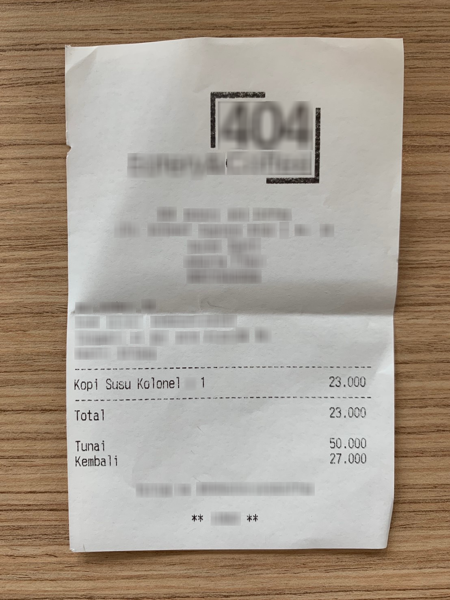

In [16]:
idx = missed.iloc[1]["index"]   # erster Fehlschlag; Zahl 0 ändern, um andere anzusehen

record = load_ocr("../results/ocr/validation.json")["records"][idx]
print(f"Zettel {idx}, gesucht: {missed[missed['index'] == idx][['field', 'gt']].to_dict('records')}\n")
print("\n".join(group_into_lines(record["words"])))

img = ds["validation"][int(idx)]["image"].copy()
img.thumbnail((600, 600))
img

In [13]:
CONFUSIONS = str.maketrans({
    "O": "0", "o": "0", "Q": "0", "D": "0",
    "l": "1", "I": "1", "]": "1", "[": "1", "|": "1", "!": "1",
    "S": "5", "s": "5",
    "B": "8",
})


def field_coverage_lenient(ocr_payload, gt_strings):
    """Wie field_coverage, aber typische OCR-Verwechslungen (O->0, l->1, ...) werden vorher korrigiert."""
    rows = []
    for record in ocr_payload["records"]:
        gt = parse_ground_truth(gt_strings[record["index"]])
        lines = group_into_lines(record["words"])
        line_digits = [normalize_number(line.translate(CONFUSIONS)) or "" for line in lines]

        for section, key in FIELDS:
            gt_value = normalize_number(get_field(gt, section, key))
            if gt_value is None:
                continue
            found = any(gt_value in digits for digits in line_digits)
            rows.append({"index": record["index"], "field": f"{section}.{key}", "gt": gt_value, "found": found})
    return pd.DataFrame(rows)


cov_lenient = field_coverage_lenient(load_ocr("../results/ocr/validation.json"), val_gt)

summary["lenient"] = cov_lenient.groupby("field")["found"].mean() * 100
summary.loc["ALL", "lenient"] = cov_lenient["found"].mean() * 100
summary.round(1)

,n,default,tuned,lenient
field,,,,
sub_total.subtotal_price,67,82.1,85.1,92.5
sub_total.tax_price,47,83.0,80.9,87.2
total.cashprice,64,50.0,54.7,68.8
total.changeprice,64,68.8,65.6,78.1
total.total_price,98,74.5,78.6,85.7
ALL,340,71.5,73.2,82.6
